# Data and model audit

What this notebook does: it checks the data and the detector behind Holy-Crap against the original sources, and shows what the evidence does and does not support.

**Everything below is computed from real files.** The dataset record comes from Zenodo, the box labels are downloaded and checked against the md5 Zenodo lists, the train, validation and test split is rebuilt with the same code and seed as `training/prepare_data.py`, and the model files are checked against their `SHA256SUMS`. Nothing here is typed in by hand except the claims we compare against, and those are labelled as claims.

**What it can show**
- The data is real, published, and what we say it is (provenance, license, counts).
- The held-out test set is separate from the training files and has the size the README states.
- The model files are the ones that were reported on, and they load.

**What it cannot show yet** (the last section says why)
- That the model is *not overfit*. That needs training and validation curves, a split by farm or visit, and a lab confirmed check. None of those is in the repository today.

In [1]:
import json, os, random, re, sys, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HERE = Path.cwd() if (Path.cwd() / "hc_viz.py").exists() else Path.cwd() / "data-visualization"
sys.path.insert(0, str(HERE))
import hc_viz as hv

REPO = HERE.parent
MODEL_DIR = REPO / "models" / "dropping4-e37"
hv.style()
pd.set_option("display.max_colwidth", 110)
print("repo:", REPO)

repo: C:\Users\Reddy\Desktop\something\Holy-Crap


## 1. Where the data comes from

The farm photos and their official YOLO boxes are Zenodo record 4628934 (Machuve et al., Tanzania, 2021). The cell below asks Zenodo for the record, so the title, license and checksums are the publisher's own words.

In [2]:
ZENODO = "4628934"
rec = hv.fetch_json(f"https://zenodo.org/api/records/{ZENODO}", HERE / "data" / "zenodo_4628934.json")
m = rec["metadata"]
display(pd.DataFrame({
    "field": ["Title", "DOI", "Published", "License as listed by Zenodo", "First authors"],
    "value": [m["title"], rec["doi"], m["publication_date"], m["license"]["id"], ", ".join(c["name"] for c in m["creators"][:4]) + " and others"],
}))

files = pd.DataFrame([
    {"file": f["key"], "size_MB": round(f["size"] / 1e6, 1), "md5 listed by Zenodo": f["checksum"].split(":")[1]}
    for f in rec["files"]
]).sort_values("size_MB").reset_index(drop=True)
display(files)

,field,value
0,Title,Machine Learning Dataset for Poultry Diseases Diagnostics
1,DOI,10.5281/zenodo.4628934
2,Published,2021-02-03
3,License as listed by Zenodo,cc-by-4.0
4,First authors,"Machuve, Dina, Nwankwo, Ezinne, Mduma, Neema, Mbelwa, Hope and others"


,file,size_MB,md5 listed by Zenodo
0,imgObjDet_Yolo.zip,1.8,1f917c61c4e018b2a326d26db90a05ff
1,ncd.zip,353.5,293b3781f163b4a1cc6a25c3244690c0
2,healthy.zip,2351.6,50eb6256b840c46800c542d858f05932
3,cocci.zip,2652.5,0f0c308c48463c70b51cc3719e3a35c0
4,imgSegmentation.zip,2862.6,895aa8f40360056e7a3bccb1dba02ab4
5,salmo.zip,3118.7,33383cc8cebde24dc1ae84b0c9781509


In [3]:
label_md5 = files.loc[files.file == "imgObjDet_Yolo.zip", "md5 listed by Zenodo"].iloc[0]
zip_path = hv.download_verified(
    f"https://zenodo.org/records/{ZENODO}/files/imgObjDet_Yolo.zip?download=1",
    HERE / "data" / "imgObjDet_Yolo.zip", label_md5)
print(f"{zip_path.name}: {zip_path.stat().st_size / 1e6:.1f} MB, md5 {hv.md5(zip_path)}")
print("This equals the md5 Zenodo lists, so the labels below are the published labels: VERIFIED")

imgObjDet_Yolo.zip: 1.8 MB, md5 1f917c61c4e018b2a326d26db90a05ff
This equals the md5 Zenodo lists, so the labels below are the published labels: VERIFIED


## 2. What is in the labels

The official boxes are counted straight from the downloaded zip, using the same file layout rules as `training/prepare_data.py`. The second table compares the counts with the numbers written in our own documents.

In [4]:
CLASSES = ["cocci", "healthy", "ncd", "salmo"]          # same order as training/prepare_data.py
rows, label_files = [], {c: 0 for c in CLASSES}
with zipfile.ZipFile(zip_path) as z:
    for name in z.namelist():
        parts = name.split("/")
        if len(parts) != 3 or not parts[2].endswith(".txt") or parts[2] == "classes.txt":
            continue
        cls, stem = parts[1], parts[2][:-4]
        assert cls in CLASSES, f"unexpected folder {cls}"
        label_files[cls] += 1
        for line in z.read(name).decode(errors="ignore").splitlines():
            p = line.split()
            if len(p) == 5:
                rows.append((cls, stem, *map(float, p[1:])))
boxes = pd.DataFrame(rows, columns=["cls", "stem", "cx", "cy", "w", "h"])
boxes["area"] = boxes.w * boxes.h

order = hv.CLASS_ORDER
labels = [hv.CLASS_LABEL[c] for c in order]
colors = [hv.CLASS_COLOR[c] for c in order]
imgs = boxes.groupby("cls").stem.nunique()
nbox = boxes.groupby("cls").size()

summary = pd.DataFrame({
    "label files in zip": pd.Series(label_files), "labelled photos": imgs, "boxes": nbox, "boxes per photo": (nbox / imgs).round(2),
    "median box, share of photo": boxes.groupby("cls").area.median().round(3),
}).loc[order]
summary.index = labels
display(summary)

claimed = {"healthy": (2057, 3311), "cocci": (2103, 3075), "salmo": (2276, 2320), "ncd": (376, 384)}   # docs/vision-plan.md
display(pd.DataFrame([{
    "class": hv.CLASS_LABEL[c], "label files in our docs": a, "label files counted": label_files[c],
    "boxes in our docs": b, "boxes counted": int(nbox[c]),
    "matches": "yes" if (a, b) == (label_files[c], int(nbox[c])) else "NO",
    "files with no valid box": label_files[c] - int(imgs[c])} for c, (a, b) in claimed.items()]))
print("Our documents counted label files. Photos that have at least one box are slightly fewer, because a few label files are empty.")

,label files in zip,labelled photos,boxes,boxes per photo,"median box, share of photo"
Healthy,2057,2057,3311,1.61,0.026
Coccidiosis-like,2103,2102,3075,1.46,0.217
Salmonella-like,2276,2274,2320,1.02,0.131
Newcastle-like,376,376,384,1.02,0.123


,class,label files in our docs,label files counted,boxes in our docs,boxes counted,matches,files with no valid box
0,Healthy,2057,2057,3311,3311,yes,0
1,Coccidiosis-like,2103,2103,3075,3075,yes,1
2,Salmonella-like,2276,2276,2320,2320,yes,2
3,Newcastle-like,376,376,384,384,yes,0


Our documents counted label files. Photos that have at least one box are slightly fewer, because a few label files are empty.


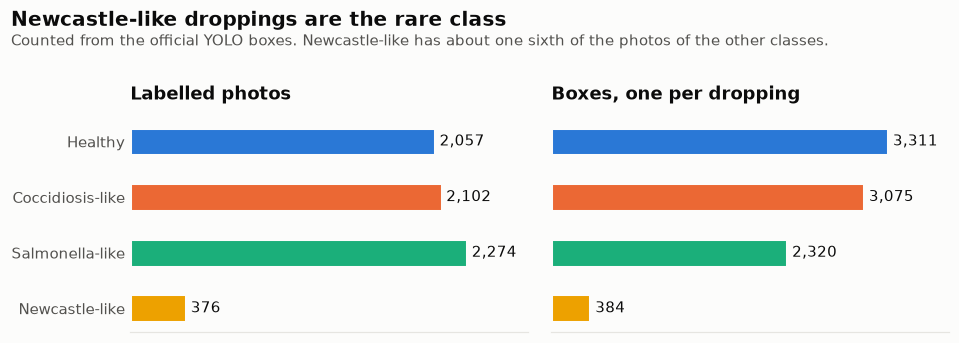

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.3), sharey=True)
hv.barh(axes[0], labels, [int(imgs[c]) for c in order], colors)
axes[0].set_title("Labelled photos")
hv.barh(axes[1], labels, [int(nbox[c]) for c in order], colors)
axes[1].set_title("Boxes, one per dropping")
axes[1].tick_params(axis="y", labelleft=False)
hv.headline(fig, "Newcastle-like droppings are the rare class",
            "Counted from the official YOLO boxes. Newcastle-like has about one sixth of the photos of the other classes.")
fig.subplots_adjust(top=0.70, wspace=0.06)
hv.savefig(fig, "01_class_balance")
plt.show()

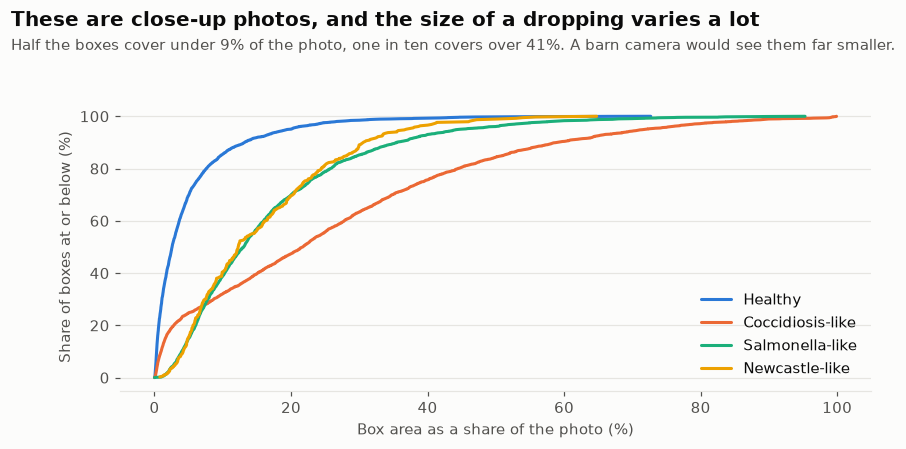

Median box covers 9% of the photo; the 90th percentile covers 41%.


In [6]:
fig, ax = plt.subplots(figsize=(8.8, 3.9))
for c in order:
    a = np.sort(boxes.loc[boxes.cls == c, "area"].to_numpy()) * 100
    ax.plot(a, np.arange(1, len(a) + 1) / len(a) * 100, color=hv.CLASS_COLOR[c], label=hv.CLASS_LABEL[c])
ax.set_xlabel("Box area as a share of the photo (%)")
ax.set_ylabel("Share of boxes at or below (%)")
ax.grid(True, axis="y")
ax.legend(loc="lower right")
med_all, p90 = boxes.area.median() * 100, boxes.area.quantile(0.9) * 100
hv.headline(fig, "These are close-up photos, and the size of a dropping varies a lot",
            f"Half the boxes cover under {med_all:.0f}% of the photo, one in ten covers over {p90:.0f}%. A barn camera would see them far smaller.")
fig.subplots_adjust(top=0.78)
hv.savefig(fig, "02_box_size")
plt.show()
print("Median box covers", f"{boxes.area.median() * 100:.0f}% of the photo; the 90th percentile covers {boxes.area.quantile(0.9) * 100:.0f}%.")

### A shortcut to watch for: how big the dropping is in the frame

If one class tends to be photographed closer than another, a model can learn *distance* instead of *appearance*. The chart shows the median box size by class. It is a flag to investigate, not proof of a shortcut, because the labels alone cannot tell us why the sizes differ.

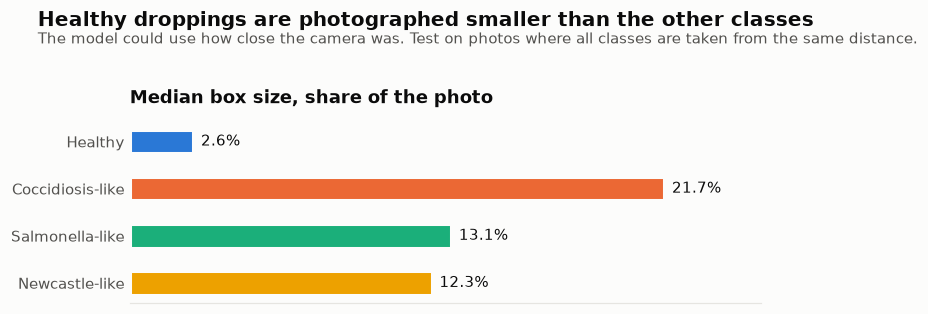

The typical abnormal box is about 6x the size of the typical healthy box in the frame.


In [7]:
med = {c: float(boxes.loc[boxes.cls == c, "area"].median()) for c in order}
fig, ax = plt.subplots(figsize=(7.4, 3.0))
hv.barh(ax, labels, [med[c] * 100 for c in order], colors, fmt="{:.1f}%")
ax.set_title("Median box size, share of the photo")
hv.headline(fig, "Healthy droppings are photographed smaller than the other classes",
            "The model could use how close the camera was. Test on photos where all classes are taken from the same distance.")
fig.subplots_adjust(top=0.66)
hv.savefig(fig, "02b_size_by_class")
plt.show()
ratio = np.mean([med[c] for c in ("cocci", "salmo", "ncd")]) / med["healthy"]
print(f"The typical abnormal box is about {ratio:.0f}x the size of the typical healthy box in the frame.")

## 3. Rebuilding the train, validation and test split

`training/prepare_data.py` splits each class 80/10/10 by photo with `random.Random(0)`. Because the shuffle is deterministic, the same split can be rebuilt from the label file alone. The model README says the held-out test set is **679 farm images never used in training**, so that is a claim we can check.

One assumption is stated openly: the original script lists photos from the class zips and keeps the ones that have labels. Here every labelled photo is assumed to have its image. If the 679 comes out exactly, that assumption holds in practice.

In [8]:
SEED = 0
split_of = {}
for cls in CLASSES:
    stems = sorted({s for c, s in zip(boxes.cls, boxes.stem) if c == cls})
    random.Random(SEED).shuffle(stems)
    n = max(1, len(stems) // 10)
    for name, part in (("test", stems[:n]), ("val", stems[n:2 * n]), ("train", stems[2 * n:])):
        for s in part:
            split_of[(cls, s)] = name
boxes["split"] = [split_of[(c, s)] for c, s in zip(boxes.cls, boxes.stem)]

photos = boxes.drop_duplicates(["cls", "stem"]).groupby(["cls", "split"]).size().unstack().loc[order][["train", "val", "test"]]
split_boxes = boxes.groupby(["cls", "split"]).size().unstack().loc[order][["train", "val", "test"]]
photos.index = split_boxes.index = labels
display(pd.concat({"photos": photos, "boxes": split_boxes}, axis=1))

test_photos = int(photos["test"].sum())
no_overlap = boxes.groupby(["cls", "stem"]).split.nunique().max() == 1
ncd_extra = 2 * int(photos.loc["Newcastle-like", "train"])
print(f"Test photos rebuilt: {test_photos}.  README claim: 679.  Match: {test_photos == 679}")
print(f"A photo is in exactly one split: {no_overlap}")
print(f"Entries in train.txt after the 3x Newcastle-like oversampling: {int(photos['train'].sum()) + ncd_extra} "
      f"({int(photos['train'].sum())} photos plus {ncd_extra} repeats, train only)")
assert test_photos == 679 and no_overlap

photos           boxes          
split             train  val test train  val test
Healthy            1647  205  205  2654  345  312
Coccidiosis-like   1682  210  210  2478  293  304
Salmonella-like    1820  227  227  1855  235  230
Newcastle-like      302   37   37   308   39   37

Test photos rebuilt: 679.  README claim: 679.  Match: True
A photo is in exactly one split: True
Entries in train.txt after the 3x Newcastle-like oversampling: 6055 (5451 photos plus 604 repeats, train only)


In [9]:
src = (REPO / "training" / "prepare_data.py").read_text().splitlines()
print("Where the oversampling happens in training/prepare_data.py (it must only touch train):")
for i, line in enumerate(src, 1):
    if "reps =" in line or "random.Random(SEED).shuffle(stems)" in line or "n_val = n_test" in line:
        print(f"  line {i}: {line.strip()}")

Where the oversampling happens in training/prepare_data.py (it must only touch train):
  line 242: random.Random(SEED).shuffle(stems)
  line 243: n_val = n_test = max(1, len(stems) // 10)
  line 252: reps = args.ncd_oversample if (split == "train" and cls == "ncd") else 1


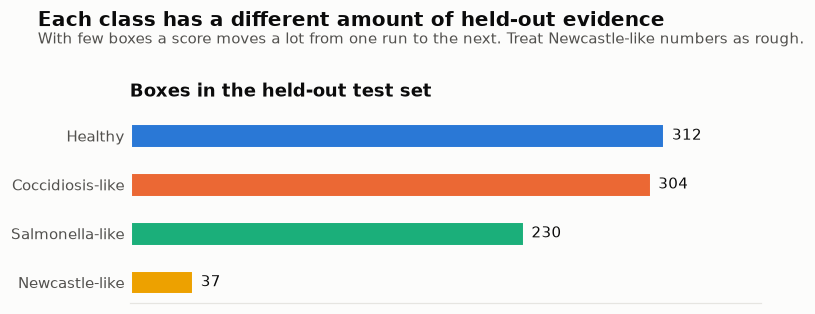

In [10]:
test_boxes = [int(split_boxes.loc[hv.CLASS_LABEL[c], "test"]) for c in order]
fig, ax = plt.subplots(figsize=(7.4, 3.0))
hv.barh(ax, labels, test_boxes, colors)
ax.set_title("Boxes in the held-out test set")
hv.headline(fig, "Each class has a different amount of held-out evidence",
            "With few boxes a score moves a lot from one run to the next. Treat Newcastle-like numbers as rough.")
fig.subplots_adjust(top=0.68)
hv.savefig(fig, "03_test_boxes")
plt.show()

## 4. Are the model files the ones that were reported on?

`SHA256SUMS` ships next to the weights. The cell recomputes each hash. Then the 320 pixel ONNX model is loaded and run once on a plain gray image. That is a smoke test that the file is a working model, not a measurement of accuracy.

In [11]:
rows = []
for line in (MODEL_DIR / "SHA256SUMS").read_text().splitlines():
    if not line.strip():
        continue
    listed, name = line.split(maxsplit=1)
    name = name.strip().lstrip("*")
    got = hv.sha256(MODEL_DIR / name)
    rows.append({"file": name, "size_MB": round((MODEL_DIR / name).stat().st_size / 1e6, 1),
                 "sha256 listed": listed[:16] + "...", "recomputed": "match" if got == listed else "MISMATCH"})
display(pd.DataFrame(rows))

import onnxruntime as ort
sess = ort.InferenceSession(str(MODEL_DIR / "dropping4_yolo11n_320.onnx"), providers=["CPUExecutionProvider"])
inp, out = sess.get_inputs()[0], sess.get_outputs()[0]
y = sess.run(None, {inp.name: np.full((1, 3, 320, 320), 114 / 255, dtype=np.float32)})[0]
print(f"input {inp.name} {inp.shape}  ->  output {out.name} {list(y.shape)}")
print("The 8 rows are 4 box values and 4 class scores for each of", y.shape[2], "candidate boxes. The file loads and runs.")

,file,size_MB,sha256 listed,recomputed
0,dropping4_yolo11n_320.onnx,10.5,87e77e4649f37fa3...,match
1,dropping4_yolo11n_416.onnx,10.5,ca0e982ff6163699...,match
2,dropping4_yolo11n_640.onnx,10.6,47b170714a30f037...,match
3,dropping4_yolo11n.pt,5.5,62c92b22a7acc09f...,match


input images [1, 3, 320, 320]  ->  output output0 [1, 8, 2100]
The 8 rows are 4 box values and 4 class scores for each of 2100 candidate boxes. The file loads and runs.


## 5. What the model scored

These numbers are read from `test_metrics.json`, which the training job wrote for the 640 pixel model on the held-out test set. They are **reported, not recomputed here**: recomputing needs the 8.5 GB of test photos. The right panel repeats the amount of test data behind each class.

,mAP50,mAP50-95,test boxes
Healthy,0.867,0.685,312
Coccidiosis-like,0.820,0.629,304
Salmonella-like,0.913,0.585,230
Newcastle-like,0.782,0.346,37


All classes: mAP50 0.845, mAP50-95 0.561, precision 0.839, recall 0.782


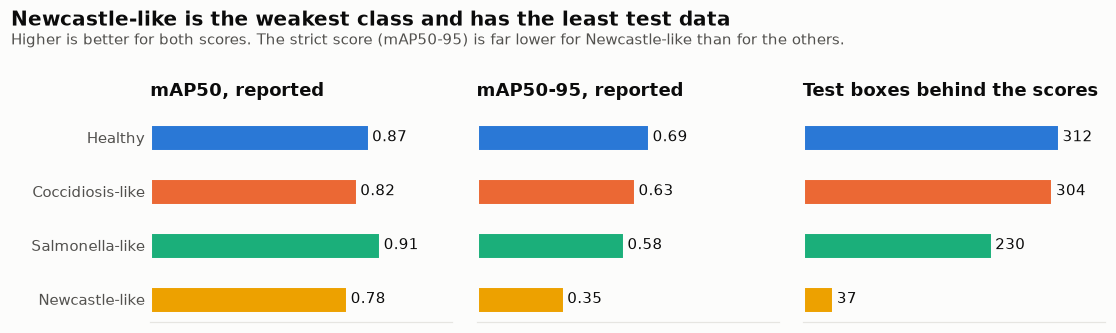

In [12]:
rep = json.loads((MODEL_DIR / "test_metrics.json").read_text())
m50, m5095 = rep["per_class_mAP50"], rep["per_class_mAP50_95"]
display(pd.DataFrame({"mAP50": m50, "mAP50-95": m5095, "test boxes": dict(zip(order, test_boxes))}).loc[order].rename(index=hv.CLASS_LABEL))
print(f"All classes: mAP50 {rep['test_mAP50']}, mAP50-95 {rep['test_mAP50_95']}, precision {rep['precision']}, recall {rep['recall']}")

fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.2), sharey=True)
hv.barh(axes[0], labels, [m50[c] for c in order], colors, fmt="{:.2f}", xmax=1.2)
axes[0].set_title("mAP50, reported")
hv.barh(axes[1], labels, [m5095[c] for c in order], colors, fmt="{:.2f}", xmax=1.2)
axes[1].set_title("mAP50-95, reported")
hv.barh(axes[2], labels, test_boxes, colors)
axes[2].set_title("Test boxes behind the scores")
for ax in axes[1:]:
    ax.tick_params(axis="y", labelleft=False)
hv.headline(fig, "Newcastle-like is the weakest class and has the least test data",
            "Higher is better for both scores. The strict score (mAP50-95) is far lower for Newcastle-like than for the others.")
fig.subplots_adjust(top=0.70, wspace=0.08)
hv.savefig(fig, "04_reported_scores")
plt.show()

## 6. Overfitting: what we can and cannot say

Overfitting means a model that does well on the data it trained on and worse on anything new. Three kinds of evidence speak to it:

1. **Training and validation curves.** If validation stops improving while training keeps improving, the model is memorising.
2. **A held-out test set that is truly independent.** Separate files are not enough if the same farm visit appears on both sides.
3. **A different source.** A model that holds up on a second farm, a lab confirmed set, or a barn camera has generalised.

The cell below looks for the Ultralytics `results.csv` and draws the curves if it exists. Set `HC_RESULTS_CSV` to point at it.

In [13]:
cands = [Path(os.environ["HC_RESULTS_CSV"])] if "HC_RESULTS_CSV" in os.environ else []
cands += [REPO / "training" / "work" / "train" / "results.csv", REPO / "training" / "runs" / "train" / "results.csv", MODEL_DIR / "results.csv"]
results_csv = next((p for p in cands if p.exists()), None)

if results_csv is None:
    print("No results.csv was found, so training and validation curves cannot be drawn.")
    print("Looked in:"); [print("  ", p.relative_to(REPO) if REPO in p.parents else p) for p in cands]
    print("To add them: copy results.csv from the training run folder (the one that holds weights/best.pt), or set HC_RESULTS_CSV.")
else:
    df = pd.read_csv(results_csv); df.columns = [c.strip() for c in df.columns]
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.4))
    axes[0].plot(df["epoch"], df["train/box_loss"], color=hv.BLUE, label="Training")
    axes[0].plot(df["epoch"], df["val/box_loss"], color=hv.CLASS_COLOR["cocci"], label="Validation")
    axes[0].set_title("Box loss, lower is better"); axes[0].set_xlabel("Epoch"); axes[0].grid(True, axis="y"); axes[0].legend()
    axes[1].plot(df["epoch"], df["metrics/mAP50(B)"], color=hv.BLUE, label="Validation mAP50")
    axes[1].set_title("Validation mAP50, higher is better"); axes[1].set_xlabel("Epoch"); axes[1].grid(True, axis="y")
    best_val = int(df["val/box_loss"].idxmin())
    since = int(df["epoch"].iloc[-1] - df["epoch"].iloc[best_val])
    hv.headline(fig, "Training against validation", f"Validation box loss was lowest at epoch {int(df['epoch'].iloc[best_val])}, {since} epochs before the last one logged.")
    fig.subplots_adjust(top=0.74, wspace=0.18)
    hv.savefig(fig, "05_training_curves"); plt.show()

No results.csv was found, so training and validation curves cannot be drawn.
Looked in:
   training\work\train\results.csv
   training\runs\train\results.csv
   models\dropping4-e37\results.csv
To add them: copy results.csv from the training run folder (the one that holds weights/best.pt), or set HC_RESULTS_CSV.


In [14]:
status = pd.DataFrame([
    ("A test set exists and is separate from the training files", "Verified", "Rebuilt the split, 679 test photos, each photo in one split (section 3)."),
    ("Oversampling happens after the split, in train only", "Verified", "Read the code: Newcastle-like photos are repeated only inside the train loop (section 3)."),
    ("The model files are the ones reported on", "Verified", "SHA256 recomputed and matching; the ONNX file loads and runs (section 4)."),
    ("Test scores are real numbers from the run", "Reported", "Read from test_metrics.json. Not recomputed here, the test photos are not in the repo."),
    ("Training and validation curves", "Found" if results_csv else "Not available", "results.csv " + ("was found and plotted above." if results_csv else "is not in the repository.")),
    ("Split by farm or visit", "Not available", "The split is random by photo. The model README says the same farm can appear on both sides."),
    ("Photo distance as a shortcut", "Flag", f"Healthy boxes are far smaller in frame (median {med['healthy'] * 100:.1f}% of the photo) than the other classes ({min(med[c] for c in ('cocci','salmo','ncd')) * 100:.0f} to {max(med[c] for c in ('cocci','salmo','ncd')) * 100:.0f}%). Needs a same distance test."),
    ("Near duplicate photos across splits", "Not done", "Needs the images. A perceptual hash pass would show whether neighbouring shots leak across the split."),
    ("Lab confirmed (PCR) check", "Not done", "The model README says it has not been run yet."),
    ("Final model", "Interim", "The snapshot is epoch 37 of 100, an interim checkpoint."),
], columns=["Check", "Status", "Evidence"])
tone = {"Verified": "#d7f0e4", "Found": "#d7f0e4", "Reported": "#e3ebf8", "Interim": "#fbf0d2", "Flag": "#fbf0d2", "Not done": "#f6d9d6", "Not available": "#f6d9d6"}
display(status.style.apply(lambda col: [f"background-color: {tone[v]}; color: #0b0b0b" if col.name == "Status" else "" for v in status["Status"]], axis=0).hide(axis="index"))

Check,Status,Evidence
A test set exists and is separate from the training files,Verified,"Rebuilt the split, 679 test photos, each photo in one split (section 3)."
"Oversampling happens after the split, in train only",Verified,Read the code: Newcastle-like photos are repeated only inside the train loop (section 3).
The model files are the ones reported on,Verified,SHA256 recomputed and matching; the ONNX file loads and runs (section 4).
Test scores are real numbers from the run,Reported,"Read from test_metrics.json. Not recomputed here, the test photos are not in the repo."
Training and validation curves,Not available,results.csv is not in the repository.
Split by farm or visit,Not available,The split is random by photo. The model README says the same farm can appear on both sides.
Photo distance as a shortcut,Flag,Healthy boxes are far smaller in frame (median 2.6% of the photo) than the other classes (12 to 22%). Needs a same distance test.
Near duplicate photos across splits,Not done,Needs the images. A perceptual hash pass would show whether neighbouring shots leak across the split.
Lab confirmed (PCR) check,Not done,The model README says it has not been run yet.
Final model,Interim,"The snapshot is epoch 37 of 100, an interim checkpoint."


### Reading of the evidence

**Supported:** the data is the published Zenodo dataset and our counts match it exactly. The held-out test set is separate from the training files and is the size the README states. The weights are the files that were reported on. On that random-split test set the detector reaches the reported 0.845 mAP50, which shows it learned the task on this dataset.

**Flagged:** healthy droppings are photographed much smaller in frame than the other classes, so photo distance could act as a shortcut. That should be tested before trusting any class level score.

**Not supported yet:** that the model does not overfit, and that it will hold up in a new barn. A random split by photo can put pictures from the same farm visit on both sides, which flatters the score. The Newcastle-like class has little test data, so its scores are uncertain. The model is an interim checkpoint, and no curves or lab confirmed check are in the repo.

**What would close the gap**
1. Commit `results.csv` from the training run and re-run this notebook. It will draw the curves.
2. Run the lab confirmed (PCR) subset, record 5801834, as a second source. A large drop there would mean overfitting to the farm photos.
3. Re-split by farm or visit if that metadata can be recovered from the authors, or hold out whole collection batches.
4. Run a perceptual hash check for near duplicates across splits.
5. Test the detector on photos where every class is taken from the same distance, to rule out the size shortcut.
6. Report scores with their test counts, as here, and retrain the final model before quoting any number.

In [15]:
out = HERE / "figures"
summary.to_csv(out / "summary_by_class.csv")
pd.concat({"photos": photos, "boxes": split_boxes}, axis=1).to_csv(out / "split_counts.csv")
status.to_csv(out / "evidence_status.csv", index=False)
print("Saved:", *sorted(p.name for p in out.iterdir()), sep="\n  ")

Saved:
  01_class_balance.png
  02_box_size.png
  02b_size_by_class.png
  03_test_boxes.png
  04_reported_scores.png
  evidence_status.csv
  split_counts.csv
  summary_by_class.csv
